# SPHEREx zodiacal-light emulator — progress summary (Oct 6–7, 2026)

**Goal.** Train a fast, differentiable neural-network emulator of the Kelsall (1998) 5 μm zodiacal emission (via ZodiPy)
as a function of observing geometry, and validate it carefully before moving to real SPHEREx data.

**Data.** 423,607 SPHEREx boresight exposures spanning **139.7 days** (rows are *not* in time order), with JPL ephemerides
and the Kelsall emission along each line of sight (0.32–1.09 MJy/sr). Plus one all-sky HEALPix map (nside 256) at a
single epoch for an out-of-distribution test.

**How to run this notebook.** Top to bottom, ~5–8 minutes. Heavy training was done in `sweeps/` (≈150 runs);
this notebook **loads the saved results** from `sweeps/results/` and rebuilds every table and figure. The appendix
has an optional `RETRAIN = true` switch that retrains the recommended model from scratch (~30 min).

### Headline results (80/20 chronological split: train days 0–111.4, test days 111.4–139.7)

| stage | model | test MSE (MJy/sr)² | test rms | median \|frac. error\| |
|---|---|---|---|---|
| day 1, start | all 36 dot products, full-batch 36→32→16→1 | 3.1e-2 (≈ predicting the mean) | 0.177 | — |
| day 1 | look-direction `n·*` only, full-batch 64-64-32-16 (2000 epochs, ~2 h) | 9.3e-4 | 0.030 | — |
| night 1 | mini-batch 64-64-32-16, one-cycle LR (100 epochs, ~6 min), single seed (mean of 5) | 1.4e-4 | 0.012 | — |
| **final** | **same, 5-seed ensemble** | **9.4e-5** | **0.0097** | **0.54%** |

* **All-sky (Rung 3), inside the training domain:** rms **0.0067 MJy/sr** (previous best 0.233), median error **0.54%**,
  residuals uncorrelated with every Kelsall component.
* **Interpolation (random / 7-day / 30-day splits):** median error **~0.1%**, 100–170× better than a quadratic fit.

### Five take-aways
1. **Features must not act as clocks.** Orbit-only dot products change monotonically with time and break any
   chronological test; the 8 look-direction features (`n·*`) generalize.
2. **Mini-batching + one-cycle LR** replaces 2-hour full-batch runs with 6-minute runs that are 6× better.
3. **Seed noise is large** (~2×, up to 13× for big nets) — always compare seed means, and **average seeds** (ensemble).
4. **The remaining error is extrapolation in time:** flat to ~5 days beyond the training data, then rising steeply.
   With training data on both sides the model is ~0.1% accurate.
5. **The emulator works in-domain but not toward the Sun**, and seed spread does not warn about it — a feature-range mask does.


In [1]:
# Setup: environment, data, features, splits (zodi_setup.jl), then the sweep code:
#   mb_train.jl        — mini-batch training (schedules, validation period, target transforms)
#   extra_features.jl  — n·δ̂ feature + named feature sets
#   nb_verify_fns.jl   — verification checks (split integrity, metrics, residual plots)
#   summary_helpers.jl — loads saved results → tables (DataFrames) and figures
include(joinpath(@__DIR__, "..", "zodi_setup.jl"))
for f in ("mb_train.jl", "extra_features.jl", "nb_verify_fns.jl", "summary_helpers.jl")
    include(joinpath(@__DIR__, "..", "sweeps", f))
end
println("\nloaded; saved results live in ", RES)


  Activating project at `c:\JuliaProjects\More_zodi`


description: Zodiacal light predictions for SPHEREx pointing directions
wavelength:  5.0 micron
units:       MJy/sr
N = 423607 exposures;  emission range = (0.31956938511238003, 1.0941130974339088)
n·n     median  1.000e+00   iqr  0.000e+00
n·S     median  4.851e-03   iqr  3.475e-01
n·z     median  9.747e-03   iqr  1.361e+00
n·E     median  4.805e-03   iqr  3.475e-01
n·vS    median  1.615e-02   iqr  1.356e+00
n·vE    median  3.680e-02   iqr  1.383e+00
n·J     median -5.953e-02   iqr  2.659e+00
n·x     median  5.145e-02   iqr  8.549e-01
n·y     median -1.072e-03   iqr  5.523e-01
S·S     median  1.037e+00   iqr  1.341e-02
S·z     median  2.050e-04   iqr  6.195e-05
S·E     median  1.037e+00   iqr  1.341e-02
S·vS    median -1.048e-02   iqr  5.980e-02
S·vE    median -5.250e-03   iqr  2.289e-02
S·J     median -4.519e+00   iqr  1.400e+00
S·x     median  2.056e-01   iqr  1.095e+00
S·y     median -8.518e-01   iqr  3.210e-01
z·z     median  1.000e+00   iqr  0.000e+00
z·E     median  2.096e-04   

## 1. Data and sky coverage

* Mission span **139.7 days** (not ~150): rows are unsorted and `times[1]` is not the earliest exposure, so all
  chronological splits sort by time first.
* Solar elongation of the boresight spans **85.2°–129.7°** — below the nominal 91° avoidance limit (a sharp floor at 85.2°;
  likely the restriction in the simulated pointing is looser than published).
* The maps below bin exposures into HEALPix pixels (nside 16 ≈ one SPHEREx footprint): ~82% of the sky is observed at
  least once, two large regions never are, and much of the sky is seen at only one Sun angle.


Solar elongation over all exposures: 85.2° – 129.7° (median 90.3°)


┌ Warning: Assignment to `p` in soft scope is ambiguous because a global variable by the same name exists: `p` will be treated as a new local. Disambiguate by using `local p` to suppress this warning or `global p` to assign to the existing global variable.
└ @ nothing c:\JuliaProjects\More_zodi\elongation_map.jl:37


Sky observed at least once: 82.0% of 3072 pixels
Pixels seen at < 5° elongation spread: 37.0% of observed sky


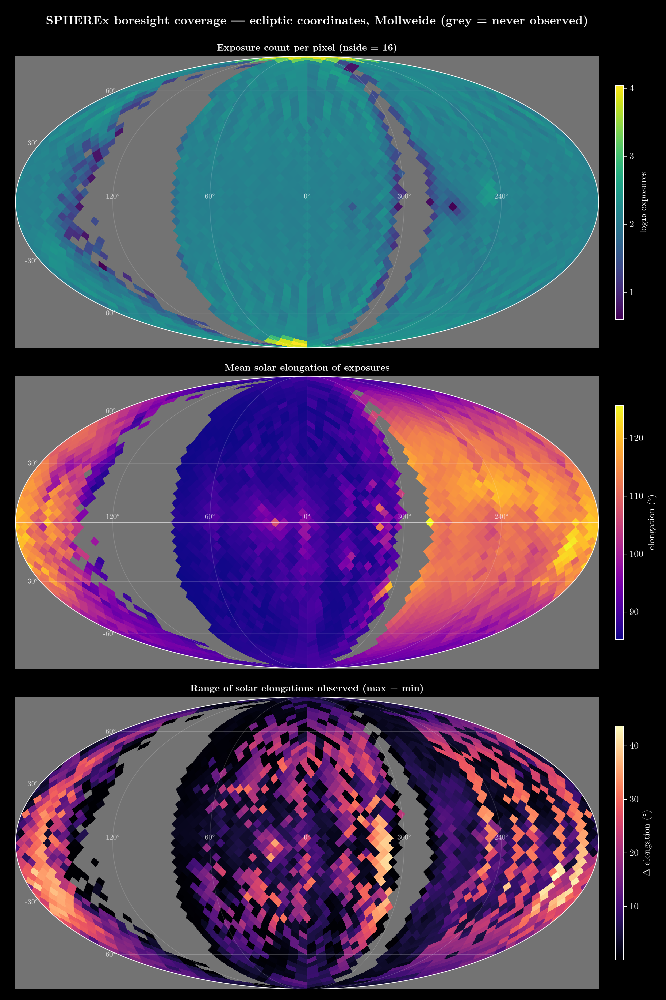

In [2]:
include(joinpath(@__DIR__, "..", "elongation_map.jl"))   # → Mollweide maps: exposure count, mean elongation, elongation range


## 2. Day 1 — why the first network failed on the 80/20 chronological split

With all 36 dot products, a 36→32→16→1 network was **no better than predicting the training mean** on the last 20% of
the mission. Reason: ~20 "orbit-only" features (`S·x`, `E·x`, `z·E`, `J·J`, …) change monotonically with time, act as
a clock, and are **outside their training range for essentially every test exposure**. The look-direction features
(`n·*`) stay in range. Training on `n·*` only fixed it; adding `S·S` (heliocentric distance², also a clock) hurt.


In [3]:
display(first(feature_shift_table(), 24))   # fraction of TEST exposures outside the TRAINING range, per feature


Row,feature,frac_test_outside,excursion_train_iqr,kind
,String,Float64,Float64,String
1,S·x,0.999976,0.215056,orbit-only
2,z·E,0.999976,2.36927,orbit-only
3,z·J,0.999976,0.509912,orbit-only
4,E·vE,0.999976,0.215218,orbit-only
5,E·x,0.999976,0.215104,orbit-only
6,vE·J,0.999976,0.287105,orbit-only
7,vE·y,0.999976,0.215398,orbit-only
8,J·J,0.999976,0.515552,orbit-only
9,J·x,0.999976,0.500396,orbit-only


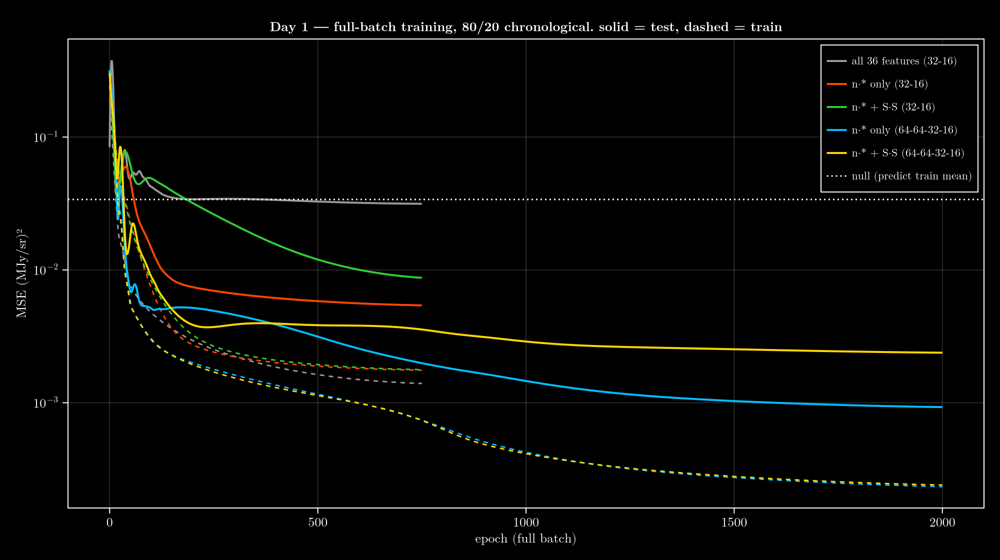

In [4]:
fullbatch_fig()   # full-batch training (day 1): all-36 vs n·* vs n·*+S·S, small and larger nets


## 3. Mini-batch training and learning-rate schedules

Mini-batching (batch 512) reached the 2-hour full-batch result in ~2 epochs (seconds). Every run then fits the training
period to ~1e-6 while the test plateaus at ~1–2e-4 by epoch ~20 → **the limit is extrapolation, not optimization.**
Three seeds per schedule show **seed-to-seed scatter (~2×) is larger than the differences between schedules**;
peak learning rates of 1e-2 are unstable (one seed 56× worse).


Row,schedule,seeds,test_seed_42,test_seed_43,test_seed_44,test_mean,train_mean
,String,Int64,String,String,String,String,String
1,one-cycle 1e-3,3,1.57e-04,1.05e-04,2.16e-04,1.59e-04,3.78e-06
2,linear 1e-3,3,1.07e-04,1.09e-04,2.08e-04,1.41e-04,3.75e-06
3,cos×exp 3e-3,3,1.98e-04,1.62e-04,2.53e-04,2.04e-04,1.53e-06
4,cos×exp 1e-2,3,1.07e-04,5.96e-03,1.69e-04,2.08e-03,3.19e-07
5,one-cycle 3e-3,1,1.73e-04,—,—,1.73e-04,1.82e-07
6,cos×exp 1e-3,1,2.26e-04,—,—,2.26e-04,1.06e-05
7,one-cycle 1e-2,1,1.38e-03,—,—,1.38e-03,5.31e-07


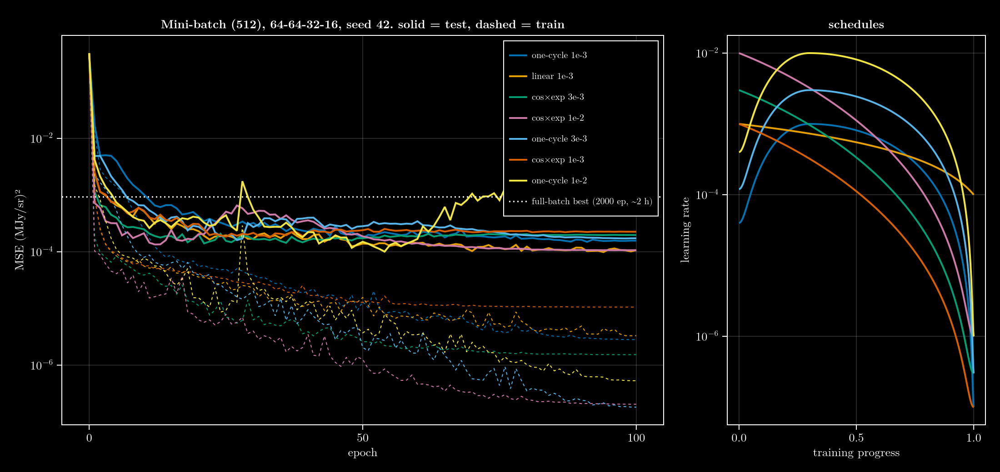

In [5]:
display(schedule_table())
schedule_fig()


## 4. Architecture scan

Bigger networks fit the training period better but **extrapolate worse and less consistently**; 64-64-32-16 (7.4k
parameters) is the sweet spot. Residual MLPs are extremely seed-sensitive (best single run of the sweep *and* some of the
worst). **Averaging seeds (★) helps every architecture**, because each seed extrapolates differently.


Row,architecture,params,seeds,test_mean,test_min,test_max,test_ensemble,train_mean,minutes_per_run
,String,Int64,Int64,String,String,String,String,String,Float64
1,mlp 32-16,833,2,6.93e-04,6.12e-04,7.73e-04,5.99e-04,2.66e-05,1.5
2,mlp 64-64-32-16,7361,7,1.55e-04,8.55e-05,2.16e-04,9.51e-05,3.76e-06,6.0
3,mlp 128-128-64-32,28033,2,2.89e-04,1.78e-04,4.01e-04,2.14e-04,1.04e-06,11.6
4,mlp 128×4-64-32,61057,2,2.79e-04,1.42e-04,4.16e-04,1.92e-04,1.29e-07,21.9
5,mlp 256-256-128-64,109313,2,8.79e-04,5.33e-04,1.23e-03,7.21e-04,1.61e-07,26.8
6,ResMLP w64×3,27649,4,4.15e-04,1.33e-04,6.81e-04,1.05e-04,1.46e-07,12.4
7,ResMLP w128×4,141569,2,4.67e-04,6.83e-05,8.66e-04,2.59e-04,6.89e-08,36.9
8,ResMLP w256×4,561665,1,1.62e-03,1.62e-03,1.62e-03,—,2.52e-07,82.3


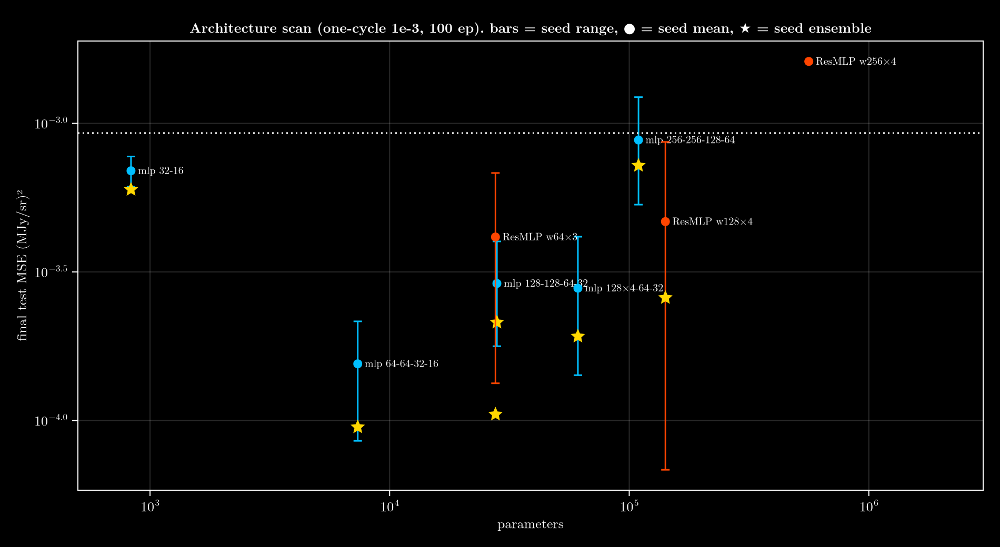

In [6]:
display(arch_table())
arch_fig()


## 5. Validation period and feature / regularization tests

Model selection now uses a **validation period**: fit on days 0–100, select on 100–111.4, report the untouched test
period 111.4–139.7. Validation ranks models like the test, except it cannot see damage that only appears further out
(dropping `n·J`). Weight decay doesn't help. `n·δ̂` (Earth-centric LEO direction) wins validation narrowly but is
rejected in §8 (it shrinks the valid sky from 33% to 6%).


Row,config,features,seeds,val_seed_mean,val_ensemble,test_seed_mean,test_ensemble,late_test_bias
,String,Int64,Int64,String,String,String,String,Float64
1,baseline n·*,8,5,3.63e-05,3.09e-05,4.29e-04,2.67e-04,-0.0144
2,+ n·δ̂,9,5,2.93e-05,2.37e-05,4.94e-04,2.70e-04,-0.0157
3,− n·J,7,5,5.26e-05,2.97e-05,1.40e-03,6.76e-04,-0.0194
4,weight decay 1e-6,8,5,3.75e-05,3.25e-05,4.30e-04,2.95e-04,-0.0158
5,weight decay 1e-5,8,5,7.74e-05,6.39e-05,7.17e-04,5.52e-04,-0.0276


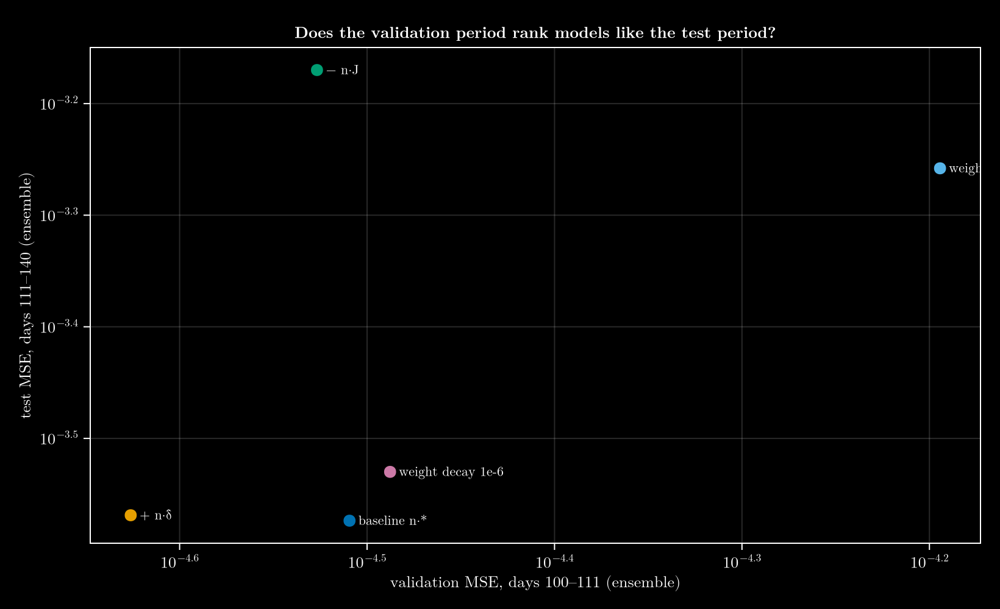

In [7]:
display(round2_table())
val_vs_test_fig()


## 6. Generalization ladder — the same recipe on every split

The network **interpolates superbly** (0.1% median error on random / 7-day / 30-day splits — 100–170× better than a
quadratic fit) and **degrades smoothly when extrapolating in time**. The second figure shows one universal curve:
error is flat out to ~5 days from the nearest training exposure, then rises steeply (×10 by ~15 days, ×1000 by ~90 days).
Polynomial baselines blow up when extrapolating (lin+quad MSE 3×10³ on chrono 25/75).


Row,split,seeds,median_gap_days,max_gap_days,null,linear,lin_quad,NN_seed_mean,NN_ensemble,rms_pct,median_abs_frac_pct
,String,Int64,Float64,Float64,String,String,String,String,String,Float64,Float64
1,random 50/50,5,0.0,0.0,2.52e-02,1.53e-02,1.49e-03,1.11e-05,9.57e-06,0.69,0.101
2,7-day alternating,5,1.83,6.7,2.57e-02,1.51e-02,1.52e-03,1.20e-05,9.87e-06,0.7,0.109
3,30-day alternating,5,7.41,15.0,2.48e-02,1.70e-02,1.56e-03,1.29e-05,8.82e-06,0.67,0.142
4,50/50 mid-mission hole,5,17.65,35.0,2.25e-02,1.62e-02,1.65e-03,4.44e-05,2.56e-05,1.15,0.307
5,chrono 85/15,3,10.55,21.1,3.76e-02,2.70e-02,3.91e-03,1.00e-04,6.38e-05,1.69,0.479
6,chrono 80/20,5,14.17,28.3,3.39e-02,2.46e-02,4.06e-03,1.42e-04,9.40e-05,2.05,0.536
7,chrono 75/25,3,17.62,35.2,3.38e-02,2.77e-02,4.48e-03,2.32e-04,1.44e-04,2.55,0.75
8,chrono 50/50,3,34.28,69.5,2.88e-02,1.52e-01,6.54e-01,2.71e-03,1.91e-03,9.42,2.012
9,chrono 25/75,3,52.85,105.2,2.60e-02,5.97e-01,3.13e+03,3.39e-03,2.93e-03,12.02,5.965


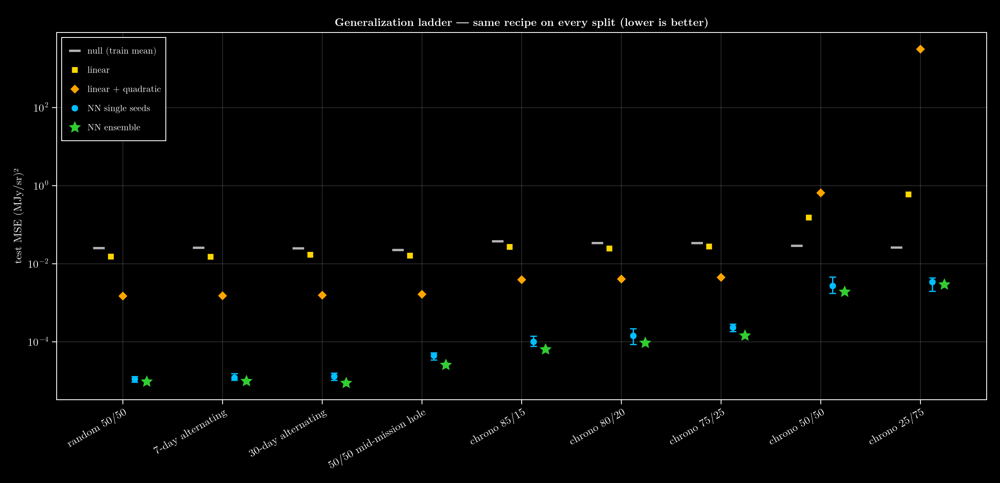

In [8]:
L = ladder_data()
display(ladder_table(L))
ladder_fig(L)


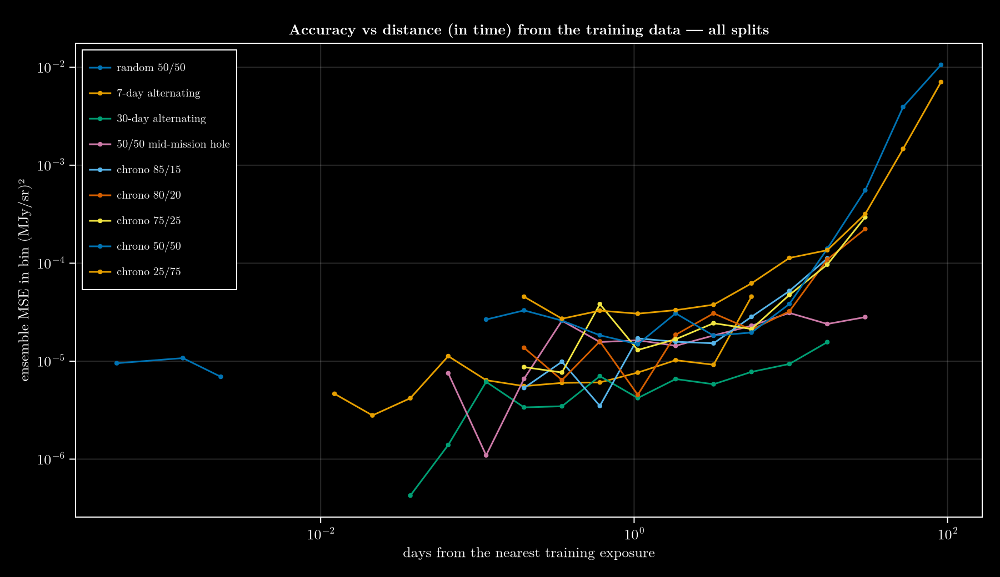

In [9]:
gap_fig(L)


## 7. Output transforms — log target, positive output, relative-error loss

Four ways to produce the output, same recipe otherwise:
* **linear** — predict y, MSE loss (baseline);
* **log target** — predict log y (MSE on log y ≈ squared *fractional* error; exp(·) is always positive);
* **softplus output** — predict y through a softplus layer (always positive);
* **relative-error loss** — predict y, loss mean(((ŷ − y)/y)²).

**Result.** No variant — not even the plain linear output — ever predicts a negative value, so positivity constraints
are not needed for this emulator. The **log target wins on validation and on all-sky fractional error**, and removes the
late-test negative drift, but it is **1.4× worse on the chronological test and much more seed-sensitive**. That is the
same pattern seen when dropping `n·J`: a validation period 0–11 days out is too close to see damage that appears
further away. **Linear output stays the recommendation; the log target is the promising alternative**, especially for
fractional accuracy and behaviour toward the Sun.


In [10]:
display(target_table())       # 80/20 chronological; val = 3 seeds fit on days 0–100, test = 5 seeds fit on days 0–111.4


Row,output,val_seed_mean,val_ensemble,test_seed_mean,test_seed_range,test_ensemble,test_median_abs_frac_pct,min_prediction
,String,String,String,String,String,String,Float64,Float64
1,"linear output, MSE (baseline)",3.67e-05,3.22e-05,1.42e-04,8.55e-05 – 2.16e-04,9.40e-05,0.536,0.318
2,log target,3.50e-05,1.84e-05,5.66e-04,1.47e-04 – 1.30e-03,1.35e-04,0.541,0.32
3,softplus output,5.16e-05,2.64e-05,3.64e-04,1.14e-04 – 9.75e-04,1.05e-04,0.479,0.319
4,relative-error loss,4.59e-05,3.82e-05,2.27e-04,1.82e-04 – 2.76e-04,1.49e-04,0.432,0.32


In [11]:
display(target_allsky_table())   # all-sky behaviour of each output choice (5-seed ensembles) — ~2 min


Row,output,in_domain_rms,in_domain_median_frac_pct,out_domain_median_frac_pct,near_sun_median_frac_pct,negative_predictions
,String,Float64,Float64,Float64,Float64,Int64
1,"linear output, MSE (baseline)",0.0067,0.54,7.77,46.2,0
2,log target,0.0069,0.412,5.43,38.0,0
3,softplus output,0.0074,0.404,9.12,48.1,0
4,relative-error loss,0.0124,0.801,11.1,43.6,0


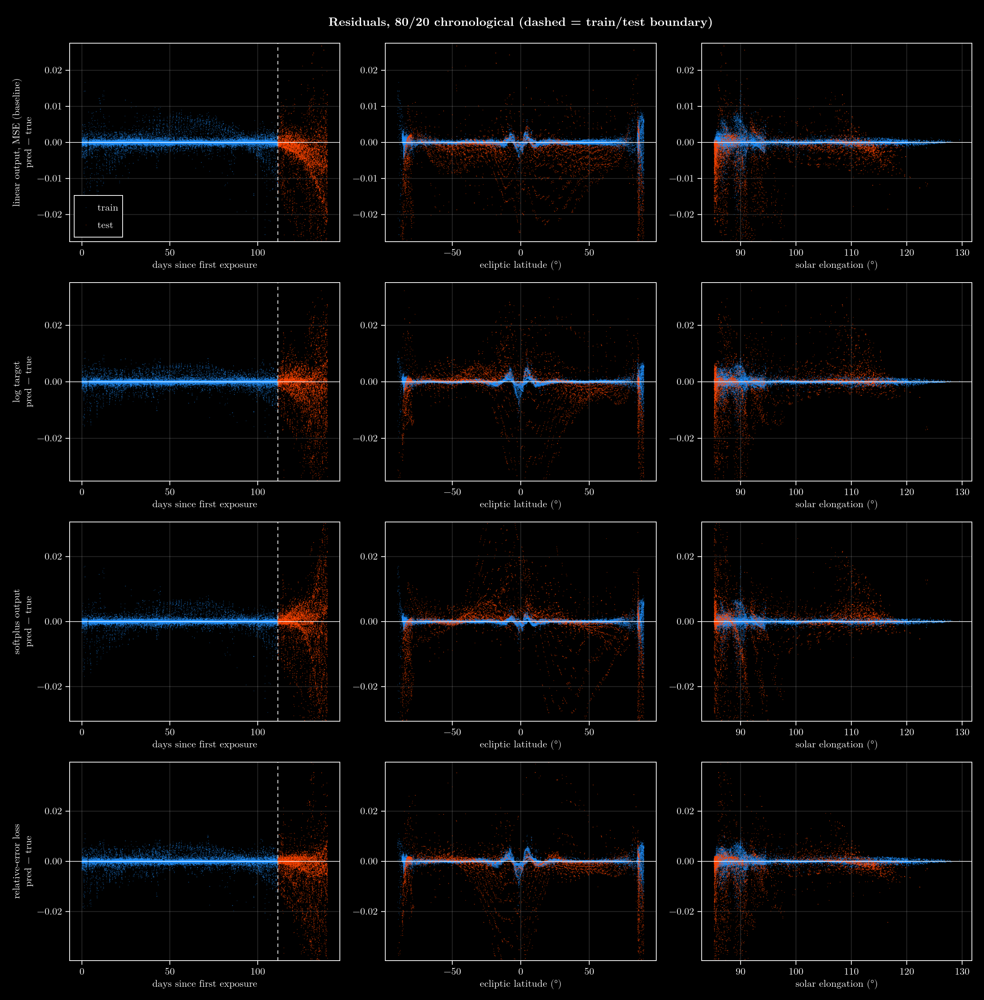

In [12]:
# residuals of each output choice (5-seed ensembles): note the linear model's late-test negative drift vs the
# more symmetric (but noisier) log-target / relative-error residuals
target_ens = Dict{String, Any}(lbl => as_ensemble(target_full_runs(t), lbl) for (lbl, t) in TARGETS)
verify_residuals(target_ens, first.(TARGETS); tag="_targets")


## 8. Final recommended model — verification

**Recipe:** the 8 look-direction features `n·*` (robustly standardized with training-row medians/IQRs) →
64 → 64 → 32 → 16 → 1 gelu MLP; batch 512; Adam with a one-cycle learning rate (peak 1e-3); 100 epochs; linear output,
MSE loss; **5 seeds (42–46) trained on days 0–111.4, predictions averaged.** Total training ≈ 30 min on a laptop CPU.

Checks: fit/test split is a clean chronological partition, normalization constants come from training rows only, stored
metrics match recomputed ones, and no negative predictions. Residual plots show the ensemble vs its best and worst seed.



=== ensemble (5 seeds) ===
  PASS split: 338885 fit (day 0.0–111.4) | 84722 test (day 111.4–139.7)
  PASS normalization: constants match training rows
  feature   test rows outside train range   furthest excursion (train σ)
  n·S          0.0%                         0.00
  n·z          0.0%                         0.00
  n·E          0.0%                         0.00
  n·vS         0.0%                         0.00
  n·vE         0.0%                         0.00
  n·J         27.0%                         0.69  ⚠ extrapolating
  n·x          0.0%                         0.00
  n·y         23.3%                         0.53  ⚠ extrapolating
run                            train MSE    test MSE   test rms   frac%   ÷null   ÷linear
ensemble (5 seeds)             2.753e-06   9.399e-05   0.0097    2.05   0.003    0.004
seed 45                        2.099e-06   8.545e-05   0.0092    1.96   0.003    0.003
seed 43                        3.924e-06   1.050e-04   0.0102    2.17   0.003    0.00

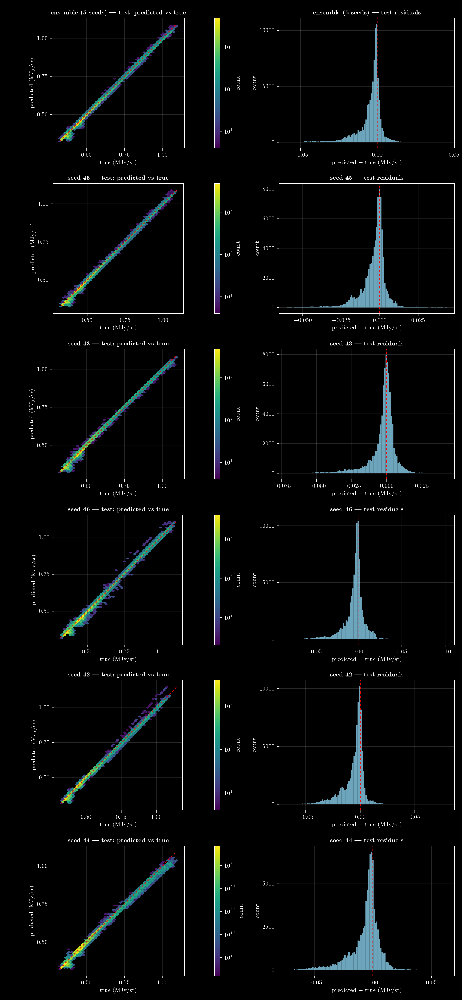

In [13]:
FINAL_TARGET = :linear                                          # output choice selected in §7
final_runs = target_full_runs(FINAL_TARGET)                     # 5 seeds, trained on days 0–111.4
fin = Dict{String, Any}("ensemble (5 seeds)" => as_ensemble(final_runs, "ensemble (5 seeds)"))
for r in final_runs; fin["seed $(r.seed)"] = r; end
seeds_sorted = sort([k for k in keys(fin) if startswith(k, "seed")], by = k -> fin[k].te_hist[end])
verify_integrity(fin, ["ensemble (5 seeds)"])
verify_metrics(fin, ["ensemble (5 seeds)", seeds_sorted...]; tag="_summary")


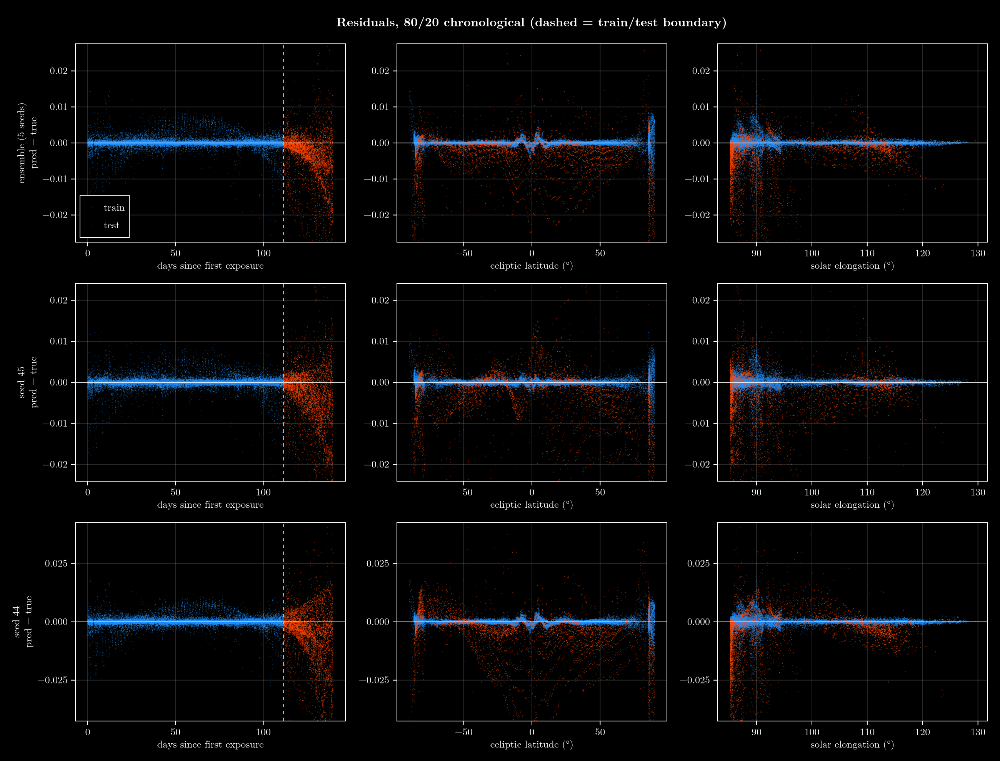

In [14]:
verify_residuals(fin, ["ensemble (5 seeds)", first(seeds_sorted), last(seeds_sorted)]; tag="_summary")


## 9. Rung 3 — all-sky out-of-distribution test

The full sky at one epoch, dominated by geometries SPHEREx never observes (e.g. toward the Sun). "In-domain" = pixels
whose features all lie inside their training range. Inside, the emulator matches Kelsall to ~0.5% with residuals
uncorrelated with every physical component; outside (toward the Sun) it fails, and **the seed spread does not warn
about it** — use the feature-range mask as the out-of-domain flag.


Row,region,sky_pct,rms_MJy_sr,median_abs_frac_pct,median_ensemble_std,negative_predictions
,String,Float64,Float64,Float64,Float64,Int64
1,in-domain,33.1123,0.00670989,0.539677,0.00621414,0
2,out-of-domain,66.8877,80.1707,7.77238,0.0924212,0
3,whole sky,100.0,65.5675,3.2921,0.0345887,0


Row,component,corr_with_residual_in_domain
,String,Float64
1,Earth-trailing,0.001
2,circumsolar ring,-0.001
3,dust band 1,-0.03
4,dust band 2,-0.031
5,dust band 3,0.001
6,smooth cloud,-0.08


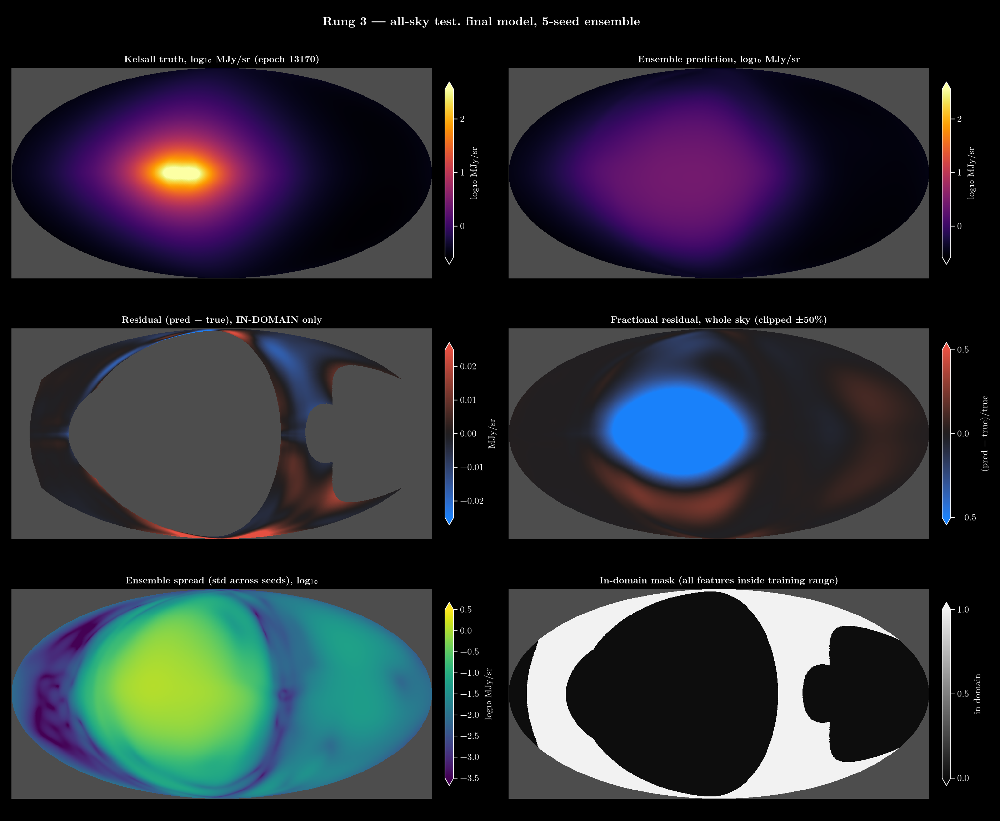

In [15]:
A = allsky_eval(final_runs; title="final model, 5-seed ensemble")
display(A.metrics); display(A.comps)
A.fig


## 10. Conclusions and next steps

**What works**
* A small (7.4k-parameter) MLP on 8 rotation-invariant look-direction features, trained with mini-batches and a one-cycle
  schedule and averaged over 5 seeds, emulates the Kelsall 5 μm sky to **~0.1% when interpolating**, **~0.5% at
  ~2 weeks beyond the training data**, and **~0.5% across the in-domain all-sky map**.
* The validation protocol, verification checks and all-sky test are reusable as-is for real data.

**What limits it**
* **Extrapolation in time.** The ladder shows a single error-vs-distance curve; the cure is training data that covers
  the period you predict (real data spanning the full year), not a bigger network.
* **Out-of-domain geometry** (toward the Sun) — an emulator can't know what it never saw; flag it with the feature-range mask.
* **Validation that sits too close to the training data** can miss problems that appear further out (`n·J`, log target).

**Open questions / next steps**
1. Why does removing the Jupiter "null" feature `n·J` hurt extrapolation? (Replace with a fixed inertial axis; check what it tracks.)
2. Log-target model: can a few more seeds or a mixed loss keep its fractional-accuracy gains without the seed sensitivity?
3. Earth-centric control from the onboarding (`S → E + δ`): confirm accuracy is unchanged before adding Earthshine/Moon features.
4. Real data: carry over the pipeline (validation period, ensembles, verification, feature-range mask); add `n·δ̂` and Moon
   features there, where they are genuine physics (Earthshine, stray light); train on the full year.


## Appendix — retrain the recommended model from scratch

Set `RETRAIN = true` to train the final recipe live (5 seeds × ~5–6 min on a laptop CPU) and compare it with the
saved runs. Training is deterministic for a given seed, so the numbers should match the saved ones.


In [16]:
RETRAIN = false
if RETRAIN
    live = [train_mb(FEATURE_SETS[:look_dir]; target=FINAL_TARGET, hidden=(64, 64, 32, 16), schedule=:onecycle,
                     lr_max=1e-3, epochs=100, batchsize=512, seed=s, label="live seed $s") for s in 42:46]
    for (a, b) in zip(live, final_runs)
        @printf("seed %d: live test MSE %.4e | saved %.4e\n", a.seed, a.te_hist[end], b.te_hist[end])
    end
    @printf("live 5-seed ensemble test MSE: %.4e\n", mse_on(ens_pred(live), live[1].te_idx))
else
    println("RETRAIN = false → using the saved runs in sweeps/results (set RETRAIN = true to retrain, ~30 min)")
end


RETRAIN = false → using the saved runs in sweeps/results (set RETRAIN = true to retrain, ~30 min)
